# Лабораторная работа №2
## Разведочный и предиктивный анализ данных
Датасет: `marketing_data.csv` — данные о клиентах магазина и их покупках.

### 1. Импорт библиотек и датасета

In [1]:
import os
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import OneHotEncoder, Binarizer, StandardScaler, MinMaxScaler

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [ ]:
df = pd.read_csv("marketing_data/marketing_data.csv")
print("Размер датасета:", df.shape)
df.head()

Размер датасета: (2240, 28)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
0,1826,1970,Graduation,Divorced,"$84,835.00",0,0,6/16/14,0,189,104,379,111,189,218,1,4,4,6,1,0,0,0,0,0,1,0,SP
1,1,1961,Graduation,Single,"$57,091.00",0,0,6/15/14,0,464,5,64,7,0,37,1,7,3,7,5,0,0,0,0,1,1,0,CA
2,10476,1958,Graduation,Married,"$67,267.00",0,1,5/13/14,0,134,11,59,15,2,30,1,3,2,5,2,0,0,0,0,0,0,0,US
3,1386,1967,Graduation,Together,"$32,474.00",1,1,5/11/14,0,10,0,1,0,0,0,1,1,0,2,7,0,0,0,0,0,0,0,AUS
4,5371,1989,Graduation,Single,"$21,474.00",1,0,4/8/14,0,6,16,24,11,0,34,2,3,1,2,7,1,0,0,0,0,1,0,SP


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   ID                   2240 non-null   int64
 1   Year_Birth           2240 non-null   int64
 2   Education            2240 non-null   str  
 3   Marital_Status       2240 non-null   str  
 4    Income              2216 non-null   str  
 5   Kidhome              2240 non-null   int64
 6   Teenhome             2240 non-null   int64
 7   Dt_Customer          2240 non-null   str  
 8   Recency              2240 non-null   int64
 9   MntWines             2240 non-null   int64
 10  MntFruits            2240 non-null   int64
 11  MntMeatProducts      2240 non-null   int64
 12  MntFishProducts      2240 non-null   int64
 13  MntSweetProducts     2240 non-null   int64
 14  MntGoldProds         2240 non-null   int64
 15  NumDealsPurchases    2240 non-null   int64
 16  NumWebPurchases      2240 non-null 

### 2. Приведение типов

In [4]:
# в названии столбца Income есть лишние пробелы, а сам доход записан строкой вида "$84,835.00"
df.columns = df.columns.str.strip()
df["Income"] = df["Income"].str.replace(r"[$,\s]", "", regex=True).astype(float)
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%m/%d/%y")
print(df[["Income", "Dt_Customer"]].dtypes)

Income                float64
Dt_Customer    datetime64[us]
dtype: object


### 3. Проверка на пропуски и дубликаты

In [5]:
missing = df.isna().sum()
print("Пропуски по столбцам:")
print(missing[missing > 0])
print("Доля пропусков в Income: {:.2%}".format(df["Income"].isna().mean()))

Пропуски по столбцам:
Income    24
dtype: int64
Доля пропусков в Income: 1.07%


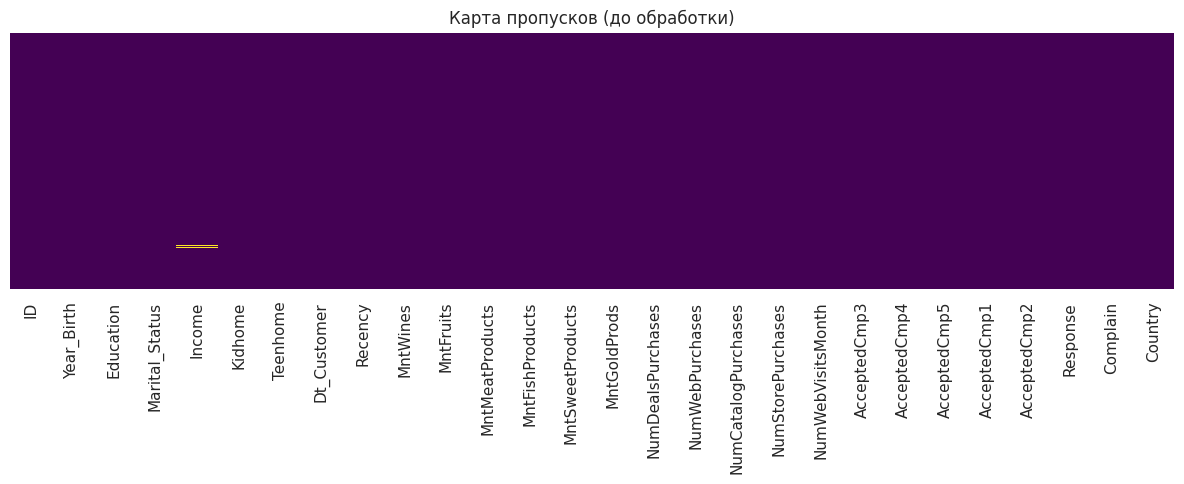

In [6]:
plt.figure(figsize=(12, 5))
sns.heatmap(df.isna(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Карта пропусков (до обработки)")
save("01_missing_before")

In [7]:
dup_full = df.duplicated().sum()
dup_no_id = df.drop(columns="ID").duplicated().sum()
print("Полных дубликатов:", dup_full)
print("Дубликатов без учета ID:", dup_no_id)
df = df.drop_duplicates(subset=df.columns.drop("ID")).reset_index(drop=True)
print("Размер после удаления дубликатов:", df.shape)

Полных дубликатов: 0
Дубликатов без учета ID: 47
Размер после удаления дубликатов: (2193, 28)


### 4. Анализ категориальных признаков

In [8]:
cat_cols = ["Education", "Marital_Status", "Country"]
for col in cat_cols:
    print(df[col].value_counts(), "\n")

Education
Graduation    1101
PhD            475
Master         366
2n Cycle       197
Basic           54
Name: count, dtype: int64 

Marital_Status
Married     845
Together    570
Single      471
Divorced    226
Widow        74
Alone         3
YOLO          2
Absurd        2
Name: count, dtype: int64 

Country
SP     1055
SA      335
CA      265
AUS     159
IND     147
GER     120
US      109
ME        3
Name: count, dtype: int64 



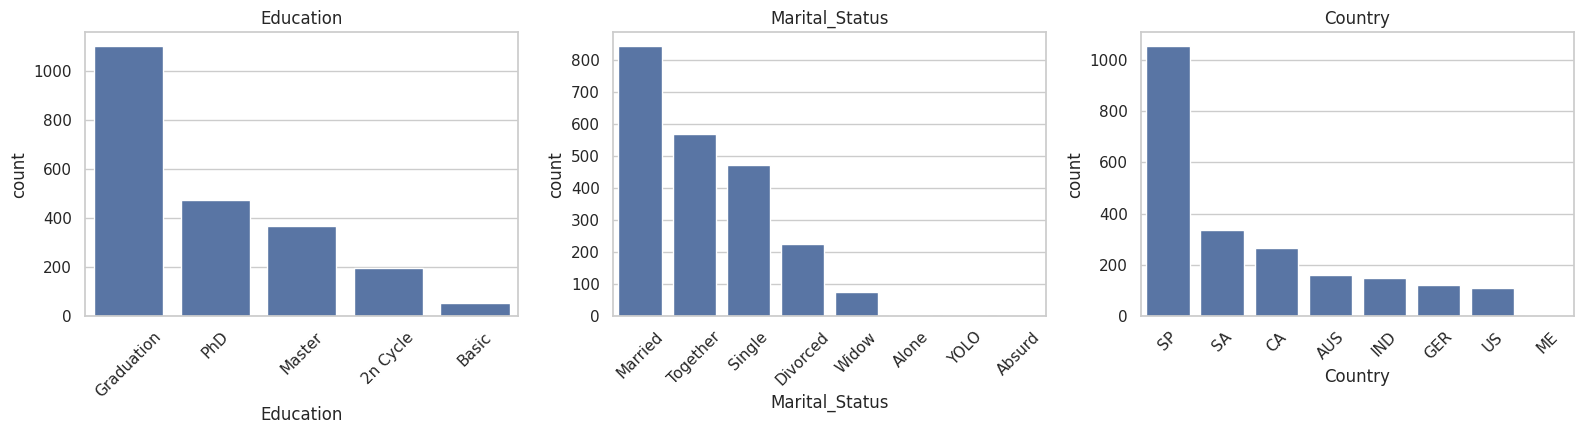

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, cat_cols):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax, color="#4C72B0")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)
save("02_categorical_before")

In [10]:
# редкие и некорректные значения семейного положения относим к Single,
# 2n Cycle по смыслу соответствует магистратуре
df["Marital_Status"] = df["Marital_Status"].replace({"Alone": "Single", "YOLO": "Single", "Absurd": "Single"})
df["Education"] = df["Education"].replace({"2n Cycle": "Master"})
print(df["Marital_Status"].value_counts(), "\n")
print(df["Education"].value_counts())

Marital_Status
Married     845
Together    570
Single      478
Divorced    226
Widow        74
Name: count, dtype: int64 

Education
Graduation    1101
Master         563
PhD            475
Basic           54
Name: count, dtype: int64


### 5. Поиск аномальных значений

In [11]:
num_cols = ["Year_Birth", "Income", "Recency", "MntWines", "MntFruits", "MntMeatProducts",
            "MntFishProducts", "MntSweetProducts", "MntGoldProds", "NumDealsPurchases",
            "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases", "NumWebVisitsMonth"]
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Year_Birth,2193.0,1968.78,12.00,1893.0,1959.0,1970.0,1977.0,1996.0
Income,2169.0,52284.82,25241.58,1730.0,35388.0,51411.0,68487.0,666666.0
Recency,2193.0,49.13,29.00,0.0,24.0,49.0,74.0,99.0
MntWines,2193.0,304.15,336.58,0.0,23.0,174.0,505.0,1493.0
MntFruits,2193.0,26.21,39.62,0.0,2.0,8.0,33.0,199.0
MntMeatProducts,2193.0,167.31,226.63,0.0,16.0,67.0,230.0,1725.0
MntFishProducts,2193.0,37.44,54.63,0.0,3.0,12.0,50.0,259.0
MntSweetProducts,2193.0,27.04,41.25,0.0,1.0,8.0,33.0,263.0
MntGoldProds,2193.0,44.18,52.37,0.0,9.0,24.0,56.0,362.0
NumDealsPurchases,2193.0,2.33,1.93,0.0,1.0,2.0,3.0,15.0


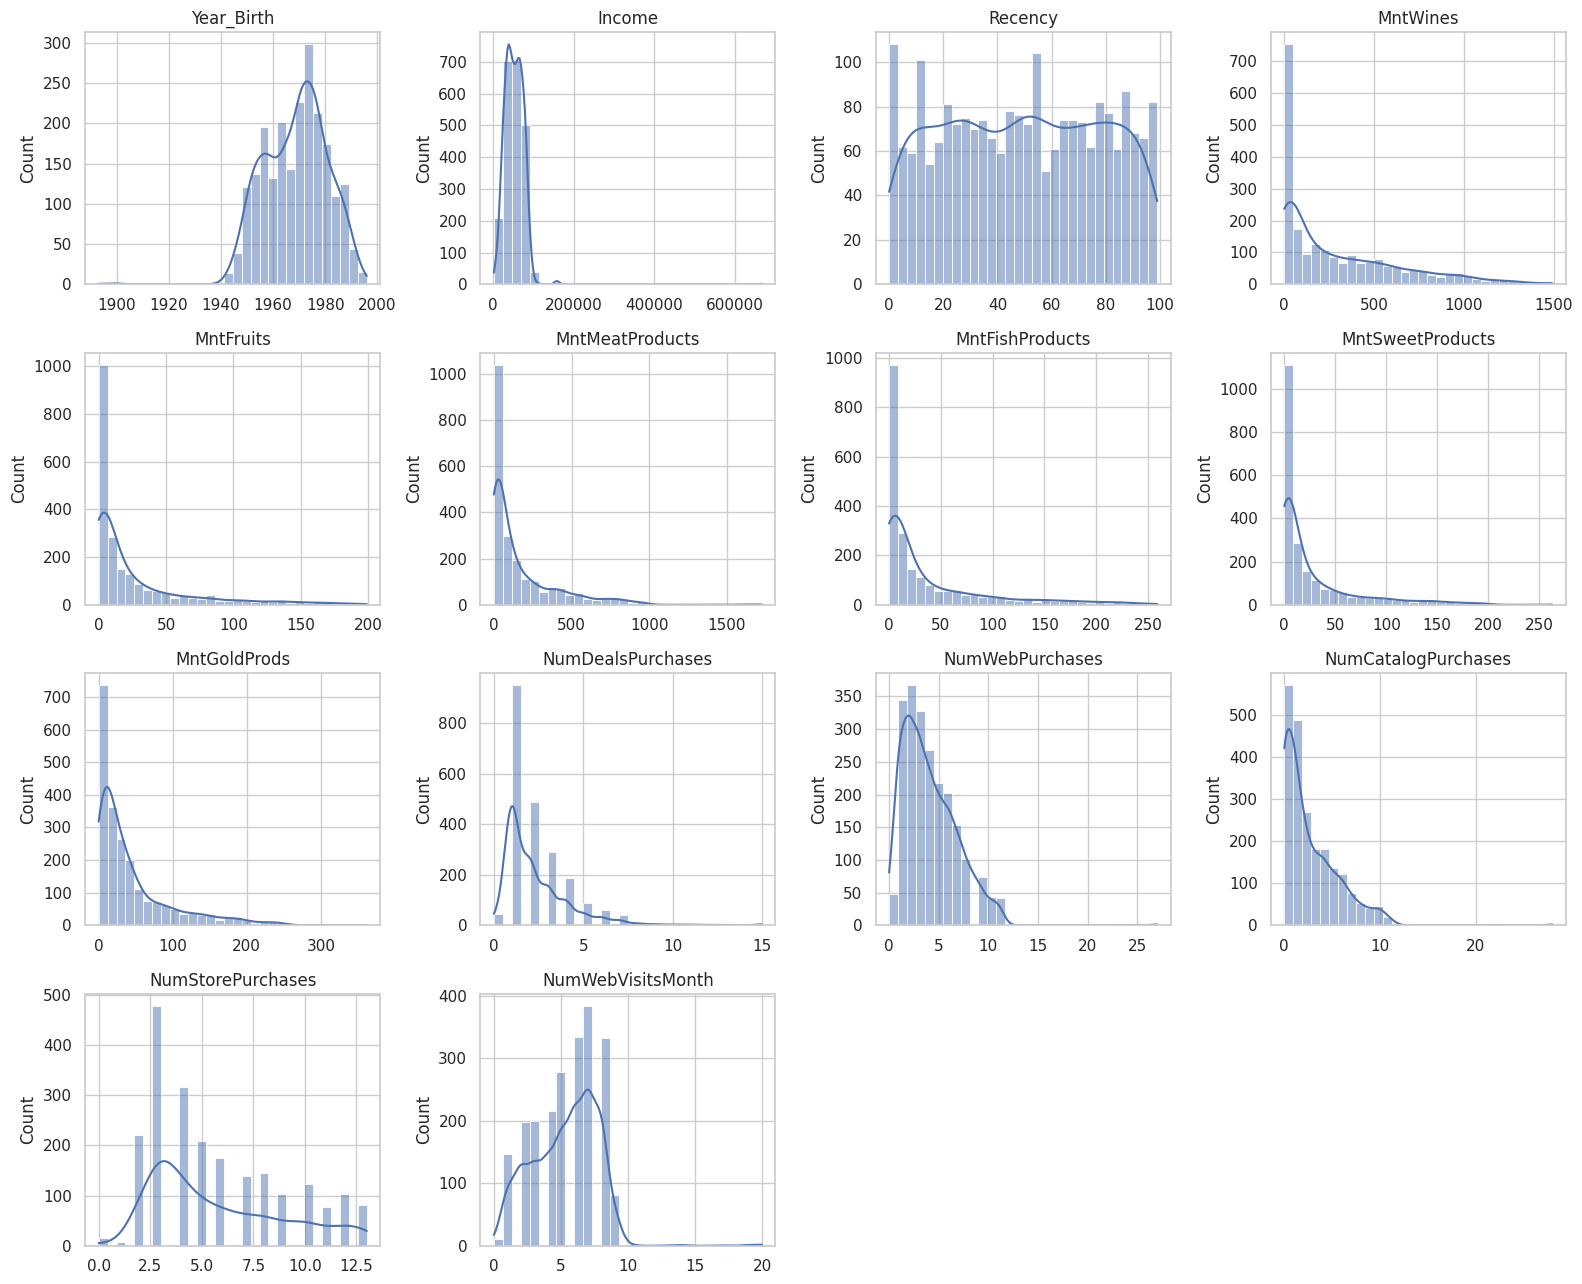

In [12]:
fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col].dropna(), bins=30, kde=True, ax=ax, color="#4C72B0")
    ax.set_title(col)
    ax.set_xlabel("")
for ax in axes.flat[len(num_cols):]:
    ax.axis("off")
save("03_hist_before")

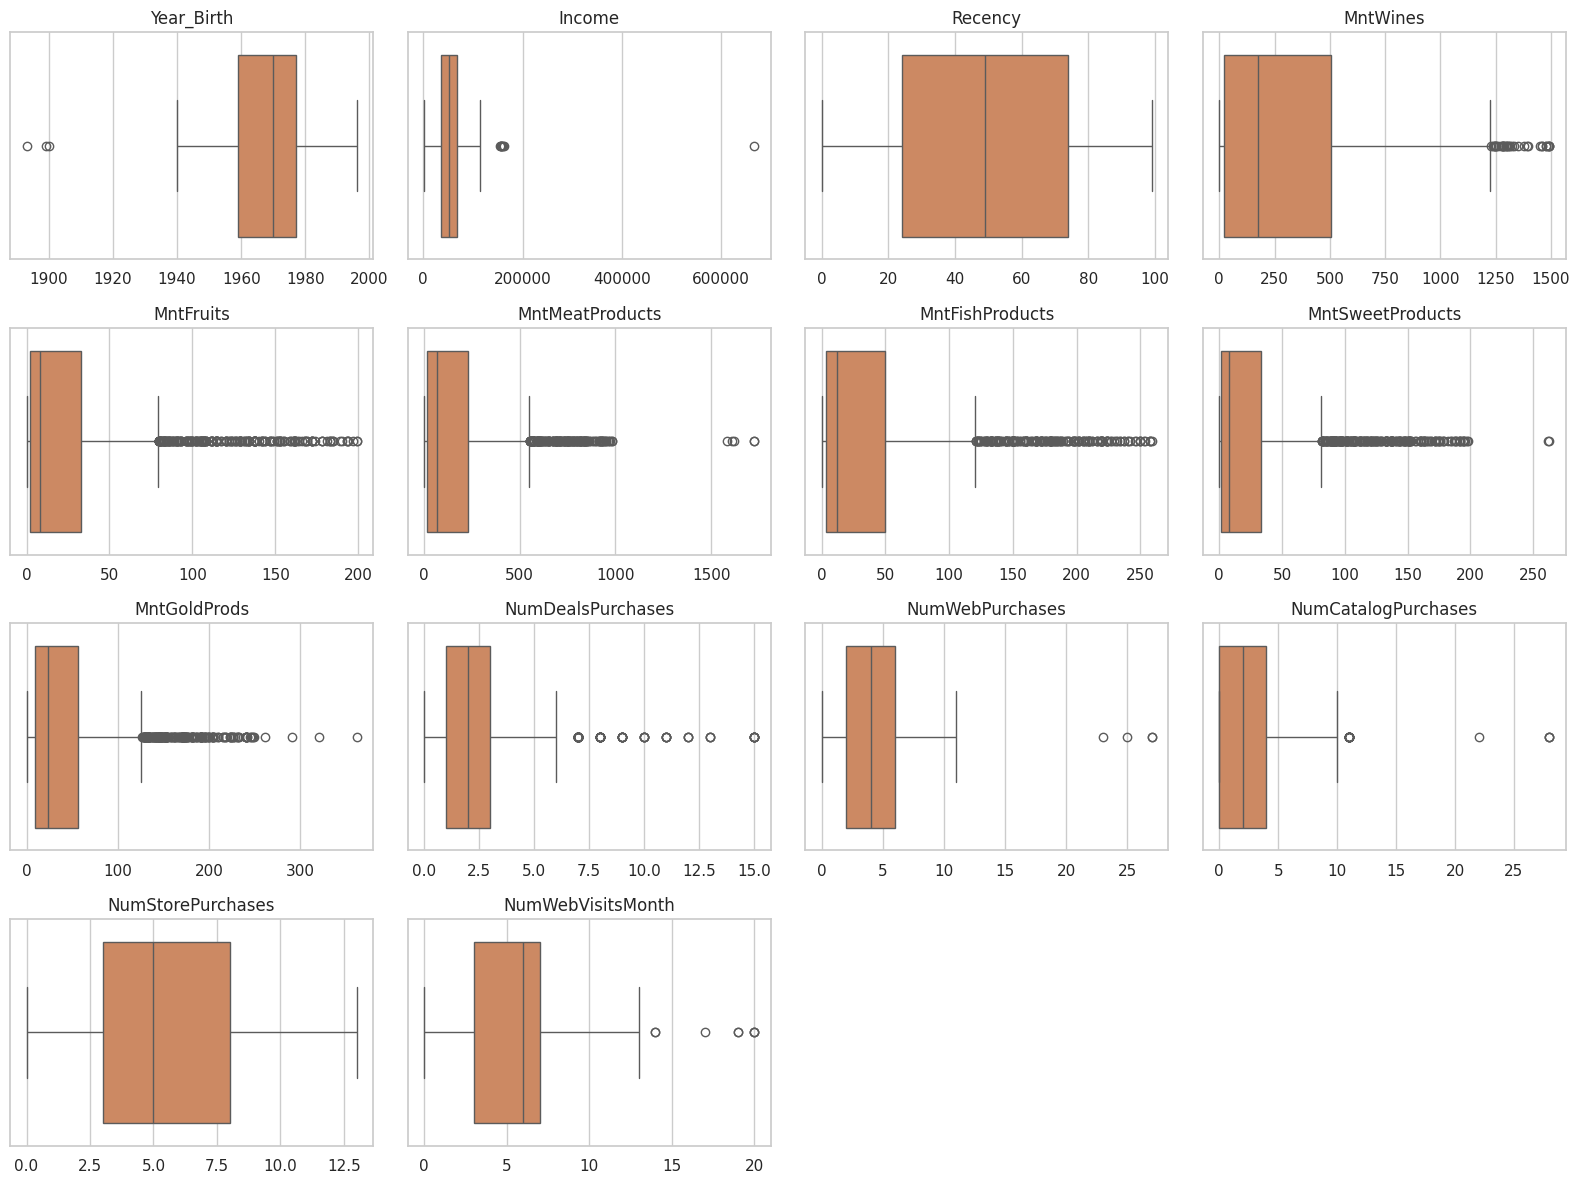

In [13]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(x=df[col], ax=ax, color="#DD8452")
    ax.set_title(col)
    ax.set_xlabel("")
for ax in axes.flat[len(num_cols):]:
    ax.axis("off")
save("04_boxplot_before")

In [14]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

rows = []
for col in num_cols:
    s = df[col].dropna()
    low, high = iqr_bounds(s)
    z = np.abs(stats.zscore(s))
    rows.append([col, round(low, 1), round(high, 1), ((s < low) | (s > high)).sum(), (z > 3).sum()])
outliers = pd.DataFrame(rows, columns=["Признак", "Нижняя граница", "Верхняя граница", "Выбросы IQR", "Выбросы |z|>3"])
outliers

,Признак,Нижняя граница,Верхняя граница,Выбросы IQR,Выбросы |z|>3
0,Year_Birth,1932.0,2004.0,3,3
1,Income,-14260.5,118135.5,8,8
2,Recency,-51.0,149.0,0,0
3,MntWines,-700.0,1228.0,35,16
4,MntFruits,-44.5,79.5,242,62
5,MntMeatProducts,-305.0,551.0,180,35
6,MntFishProducts,-67.5,120.5,216,58
7,MntSweetProducts,-47.0,81.0,241,60
8,MntGoldProds,-61.5,126.5,205,44
9,NumDealsPurchases,-2.0,6.0,84,31


Самые ранние годы рождения: [1893, 1899, 1900, 1940, 1941]
Самые большие доходы: [157243.0, 157733.0, 160803.0, 162397.0, 666666.0]


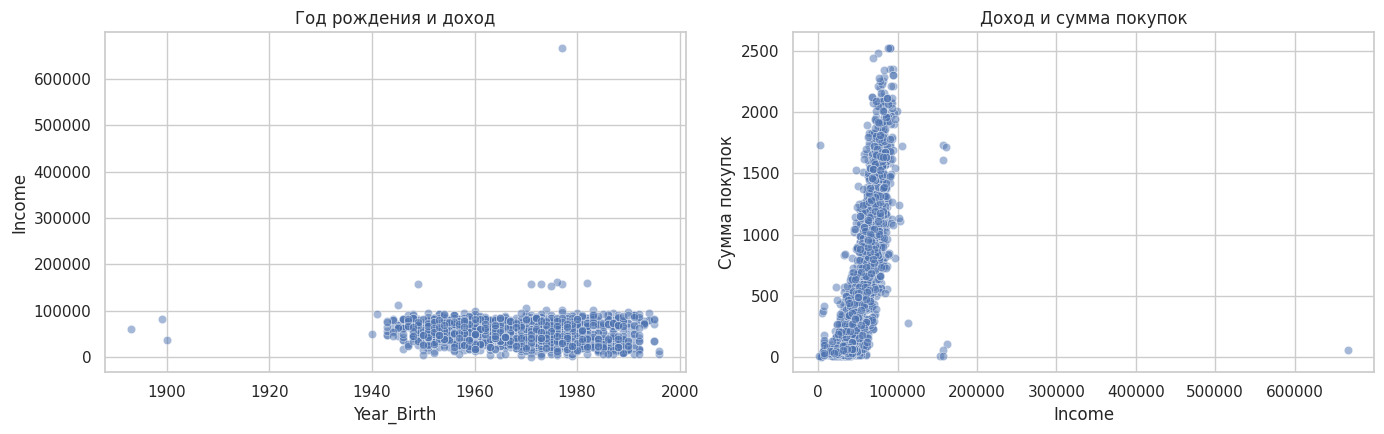

In [15]:
print("Самые ранние годы рождения:", sorted(df["Year_Birth"])[:5])
print("Самые большие доходы:", sorted(df["Income"].dropna())[-5:])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.scatterplot(data=df, x="Year_Birth", y="Income", ax=axes[0], alpha=0.5)
axes[0].set_title("Год рождения и доход")
sns.scatterplot(x=df["Income"], y=df[num_cols[3:9]].sum(axis=1), ax=axes[1], alpha=0.5)
axes[1].set_title("Доход и сумма покупок")
axes[1].set_ylabel("Сумма покупок")
save("05_scatter_anomalies")

### 6. Заполнение пропусков и устранение выбросов

In [16]:
# невозможные значения: год рождения раньше 1920 и доход 666666 заменяем на пропуски
df.loc[df["Year_Birth"] < 1920, "Year_Birth"] = np.nan
df.loc[df["Income"] > 200000, "Income"] = np.nan
print("Пропуски после пометки аномалий:")
print(df[["Year_Birth", "Income"]].isna().sum())

# пропуски в доходе заполняем медианой по уровню образования, год рождения - общей медианой
df["Income"] = df["Income"].fillna(df.groupby("Education")["Income"].transform("median"))
df["Year_Birth"] = df["Year_Birth"].fillna(df["Year_Birth"].median()).astype(int)
print("\nПропусков после заполнения:", df.isna().sum().sum())

Пропуски после пометки аномалий:
Year_Birth     3
Income        25
dtype: int64

Пропусков после заполнения: 0


In [17]:
# оставшиеся выбросы ограничиваем границами межквартильного размаха (винзоризация)
clip_cols = [c for c in num_cols if c != "Year_Birth"]
for col in clip_cols:
    low, high = iqr_bounds(df[col])
    df[col] = df[col].clip(lower=max(low, 0), upper=high)

rows = []
for col in num_cols:
    low, high = iqr_bounds(df[col])
    rows.append([col, ((df[col] < low) | (df[col] > high)).sum()])
pd.DataFrame(rows, columns=["Признак", "Выбросы IQR после обработки"])

,Признак,Выбросы IQR после обработки
0,Year_Birth,0
1,Income,0
2,Recency,0
3,MntWines,0
4,MntFruits,0
5,MntMeatProducts,0
6,MntFishProducts,0
7,MntSweetProducts,0
8,MntGoldProds,0
9,NumDealsPurchases,0


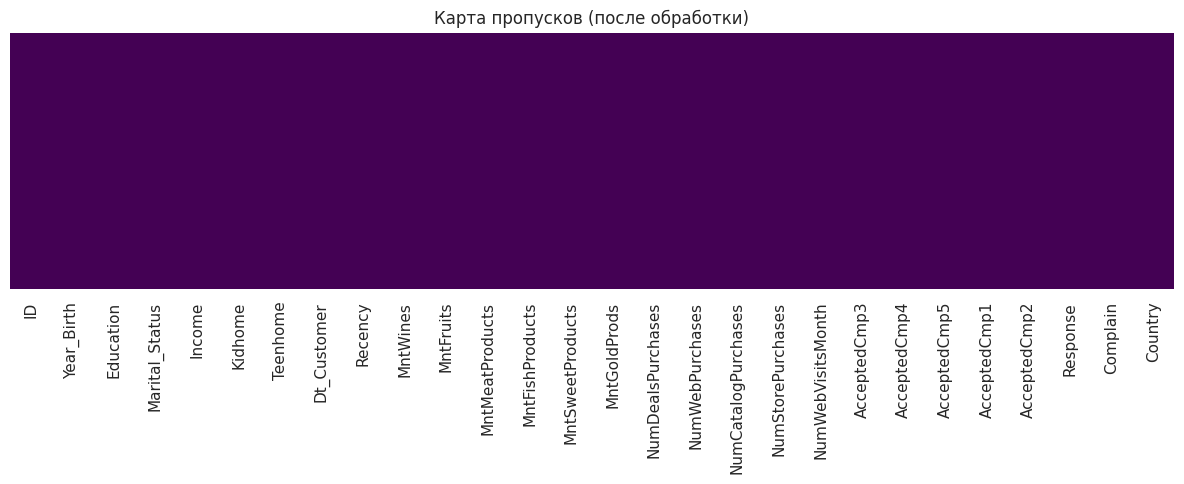

In [18]:
plt.figure(figsize=(12, 5))
sns.heatmap(df.isna(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Карта пропусков (после обработки)")
save("06_missing_after")

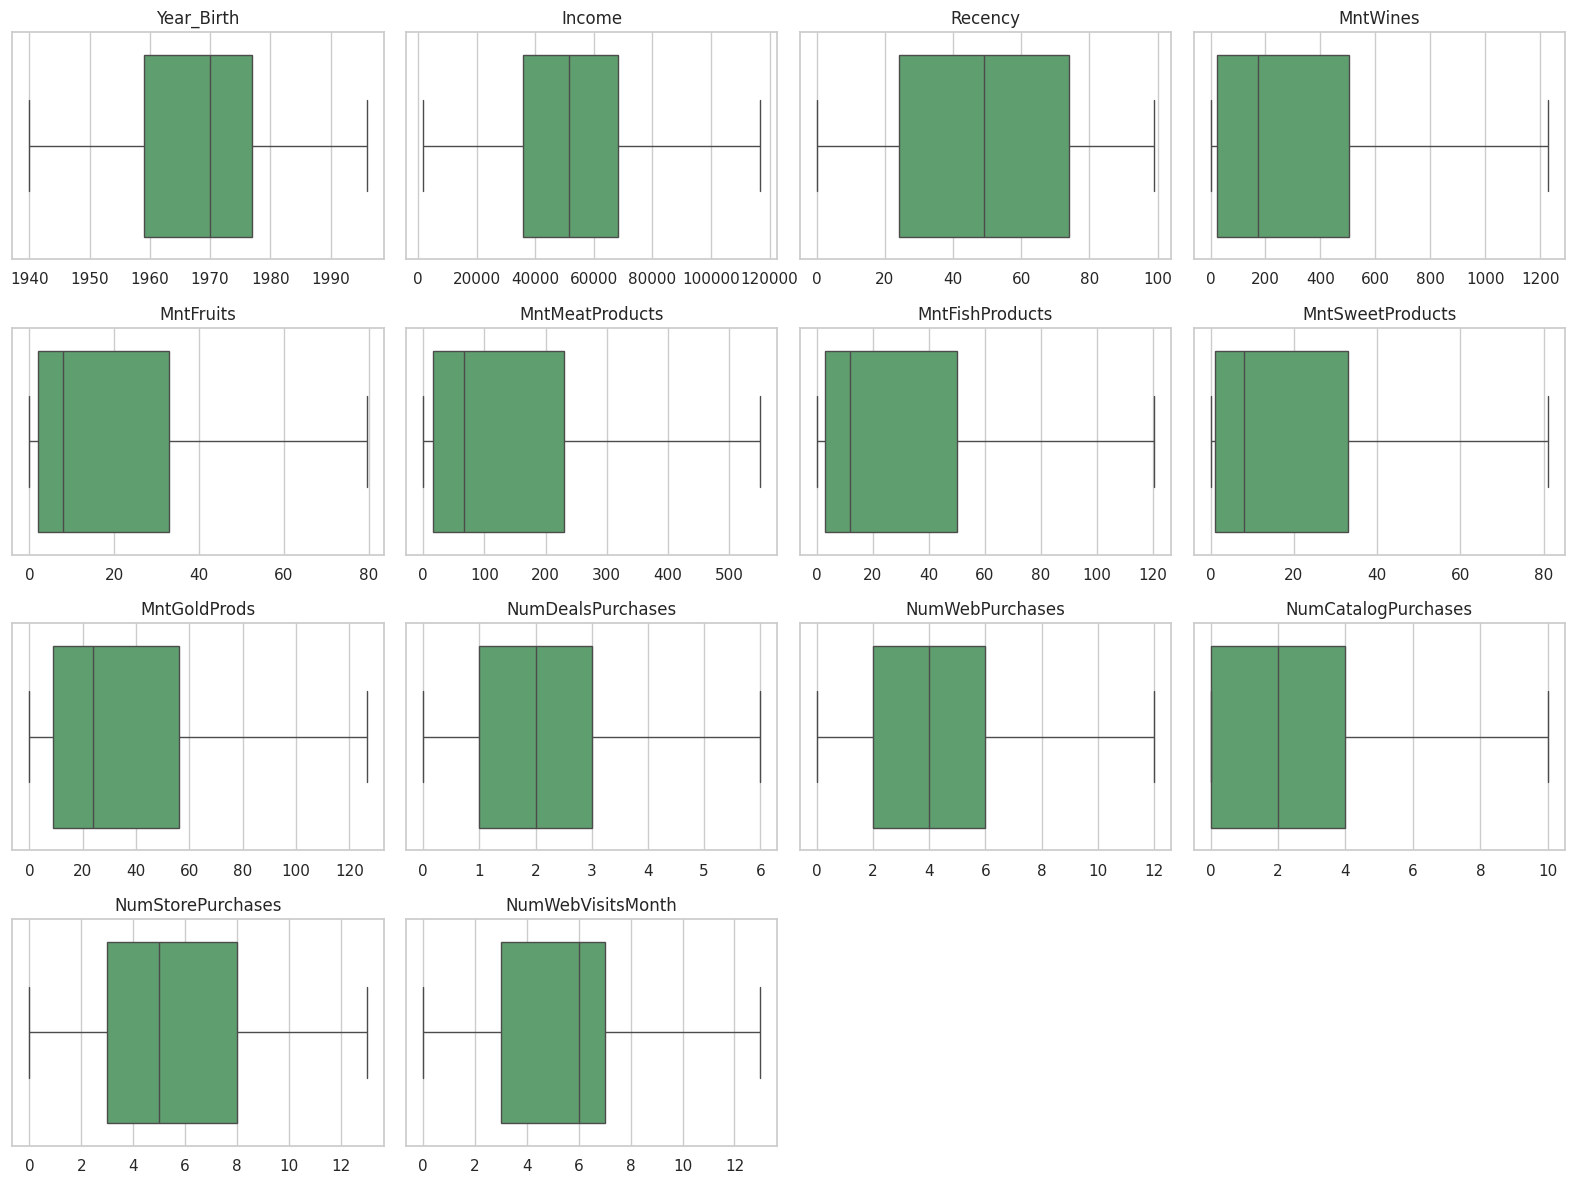

In [19]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(x=df[col], ax=ax, color="#55A868")
    ax.set_title(col)
    ax.set_xlabel("")
for ax in axes.flat[len(num_cols):]:
    ax.axis("off")
save("07_boxplot_after")

### 7. Генерация новых признаков

In [20]:
mnt_cols = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
buy_cols = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
cmp_cols = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5"]
last_date = df["Dt_Customer"].max()

df["Age"] = last_date.year - df["Year_Birth"]                    # возраст клиента
df["Children"] = df["Kidhome"] + df["Teenhome"]                  # количество детей
df["TotalSpent"] = df[mnt_cols].sum(axis=1)                      # общая сумма покупок
df["TotalPurchases"] = df[buy_cols].sum(axis=1)                  # общее количество покупок
df["AvgCheck"] = (df["TotalSpent"] / df["TotalPurchases"].replace(0, np.nan)).fillna(0).round(2)  # средний чек
df["TotalAcceptedCmp"] = df[cmp_cols].sum(axis=1)                # принято рекламных предложений
df["CustomerDays"] = (last_date - df["Dt_Customer"]).dt.days     # дней с момента регистрации

# у клиентов с одной-двумя покупками средний чек получается аномально большим, ограничиваем его по IQR
df["AvgCheck"] = df["AvgCheck"].clip(upper=iqr_bounds(df["AvgCheck"])[1])

new_cols = ["Age", "Children", "TotalSpent", "TotalPurchases", "AvgCheck", "TotalAcceptedCmp", "CustomerDays"]
df[new_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,2193.0,45.12,11.70,18.0,37.0,44.0,55.00,74.00
Children,2193.0,0.95,0.75,0.0,0.0,1.0,1.00,3.00
TotalSpent,2193.0,567.91,546.20,5.0,69.0,395.5,990.00,2097.50
TotalPurchases,2193.0,12.48,7.14,0.0,6.0,12.0,18.00,32.00
AvgCheck,2193.0,34.90,25.34,0.0,13.0,29.6,46.31,96.28
TotalAcceptedCmp,2193.0,0.30,0.68,0.0,0.0,0.0,0.00,4.00
CustomerDays,2193.0,353.39,202.52,0.0,180.0,355.0,529.00,699.00


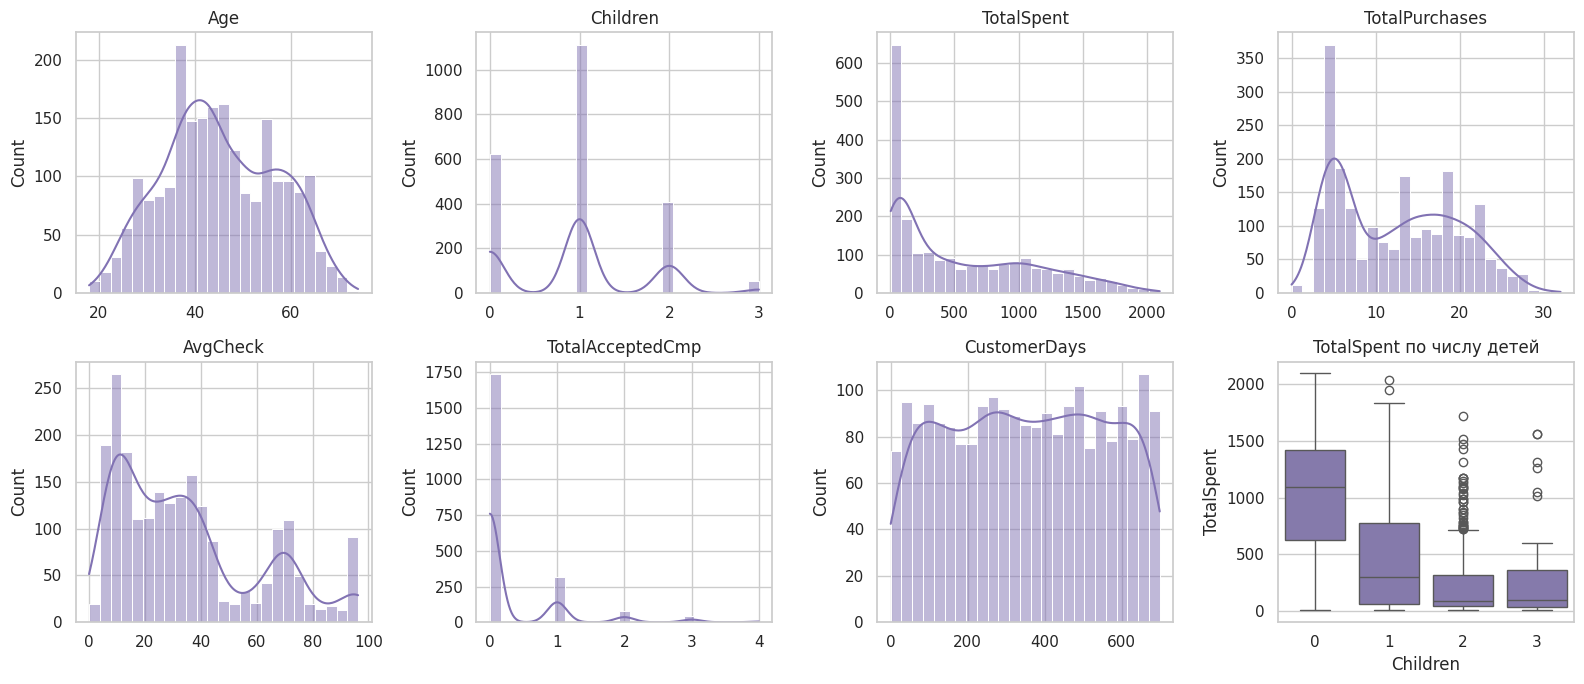

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, new_cols):
    sns.histplot(df[col], bins=25, kde=True, ax=ax, color="#8172B3")
    ax.set_title(col)
    ax.set_xlabel("")
sns.boxplot(data=df, x="Children", y="TotalSpent", ax=axes.flat[-1], color="#8172B3")
axes.flat[-1].set_title("TotalSpent по числу детей")
save("08_new_features")

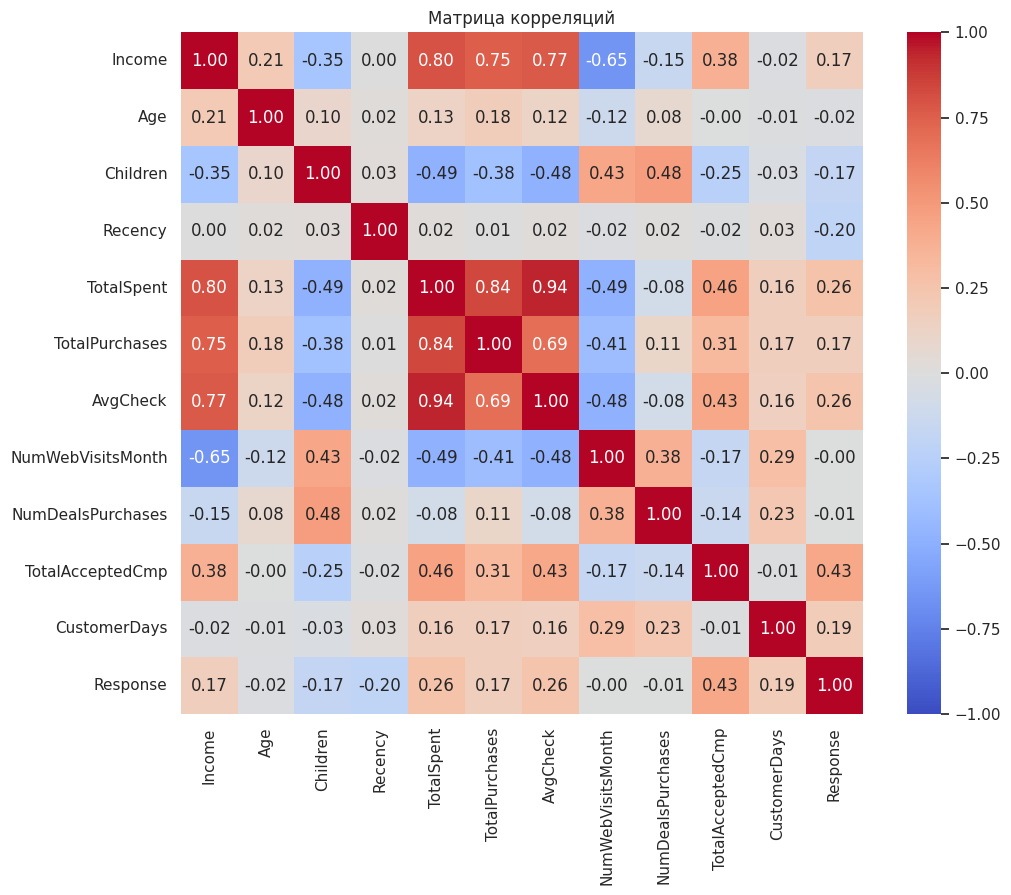

In [22]:
corr_cols = ["Income", "Age", "Children", "Recency", "TotalSpent", "TotalPurchases",
             "AvgCheck", "NumWebVisitsMonth", "NumDealsPurchases", "TotalAcceptedCmp", "CustomerDays", "Response"]
plt.figure(figsize=(11, 9))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Матрица корреляций")
save("09_corr_heatmap")

### 8. Кодирование категориальных признаков

In [23]:
# порядковое кодирование уровня образования
edu_map = {"Basic": 0, "Graduation": 1, "Master": 2, "PhD": 3}
df["Education_Code"] = df["Education"].map(edu_map)

# бинаризация: состоит ли клиент в паре, есть ли дети
df["InCouple"] = df["Marital_Status"].isin(["Married", "Together"]).astype(int)
df["IsParent"] = (df["Children"] > 0).astype(int)

# бинаризация по порогу с помощью Binarizer: доход выше медианы
binarizer = Binarizer(threshold=df["Income"].median())
df["HighIncome"] = binarizer.fit_transform(df[["Income"]]).astype(int).ravel()

df[["Education", "Education_Code", "Marital_Status", "InCouple", "Children", "IsParent", "Income", "HighIncome"]].head(8)

,Education,Education_Code,Marital_Status,InCouple,Children,IsParent,Income,HighIncome
0,Graduation,1,Divorced,0,0,0,84835.0,1
1,Graduation,1,Single,0,0,0,57091.0,1
2,Graduation,1,Married,1,1,1,67267.0,1
3,Graduation,1,Together,1,2,1,32474.0,0
4,Graduation,1,Single,0,1,1,21474.0,0
5,PhD,3,Single,0,0,0,71691.0,1
6,Master,2,Married,1,0,0,63564.0,1
7,Graduation,1,Together,1,1,1,44931.0,0


In [24]:
# One-Hot Encoding для страны и семейного положения
ohe = OneHotEncoder(sparse_output=False, dtype=int)
ohe_arr = ohe.fit_transform(df[["Country", "Marital_Status"]])
ohe_df = pd.DataFrame(ohe_arr, columns=ohe.get_feature_names_out(), index=df.index)
print("Новые OHE-признаки:")
print(textwrap.fill(", ".join(ohe_df.columns), width=100))

df_enc = pd.concat([df.drop(columns=["Education", "Marital_Status", "Country", "Dt_Customer", "ID"]), ohe_df], axis=1)
print("Размер после кодирования:", df_enc.shape)
print("Нечисловых столбцов:", df_enc.select_dtypes(exclude="number").shape[1])
ohe_df.head()

Новые OHE-признаки:
Country_AUS, Country_CA, Country_GER, Country_IND, Country_ME, Country_SA, Country_SP, Country_US,
Marital_Status_Divorced, Marital_Status_Married, Marital_Status_Single, Marital_Status_Together,
Marital_Status_Widow
Размер после кодирования: (2193, 47)
Нечисловых столбцов: 0


,Country_AUS,Country_CA,Country_GER,Country_IND,Country_ME,Country_SA,Country_SP,Country_US,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow
0,0,0,0,0,0,0,1,0,1,0,0,0,0
1,0,1,0,0,0,0,0,0,0,0,1,0,0
2,0,0,0,0,0,0,0,1,0,1,0,0,0
3,1,0,0,0,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,0,1,0,0,0,1,0,0


### 9. Стандартизация и нормализация

In [25]:
scale_cols = ["Income", "Age", "Recency", "TotalSpent", "TotalPurchases", "AvgCheck",
              "NumWebVisitsMonth", "NumDealsPurchases", "CustomerDays"] + mnt_cols

std_scaler = StandardScaler()
df_std = df_enc.copy()
df_std[scale_cols] = std_scaler.fit_transform(df_enc[scale_cols])

mm_scaler = MinMaxScaler()
df_mm = df_enc.copy()
df_mm[scale_cols] = mm_scaler.fit_transform(df_enc[scale_cols])

check = pd.DataFrame({
    "mean (std)": df_std[scale_cols].mean(),
    "std (std)": df_std[scale_cols].std(ddof=0),
    "min (minmax)": df_mm[scale_cols].min(),
    "max (minmax)": df_mm[scale_cols].max(),
}).round(3)
check

,mean (std),std (std),min (minmax),max (minmax)
Income,0.0,1.0,0.0,1.0
Age,-0.0,1.0,0.0,1.0
Recency,0.0,1.0,0.0,1.0
TotalSpent,0.0,1.0,0.0,1.0
TotalPurchases,-0.0,1.0,0.0,1.0
AvgCheck,0.0,1.0,0.0,1.0
NumWebVisitsMonth,-0.0,1.0,0.0,1.0
NumDealsPurchases,-0.0,1.0,0.0,1.0
CustomerDays,-0.0,1.0,0.0,1.0
MntWines,-0.0,1.0,0.0,1.0


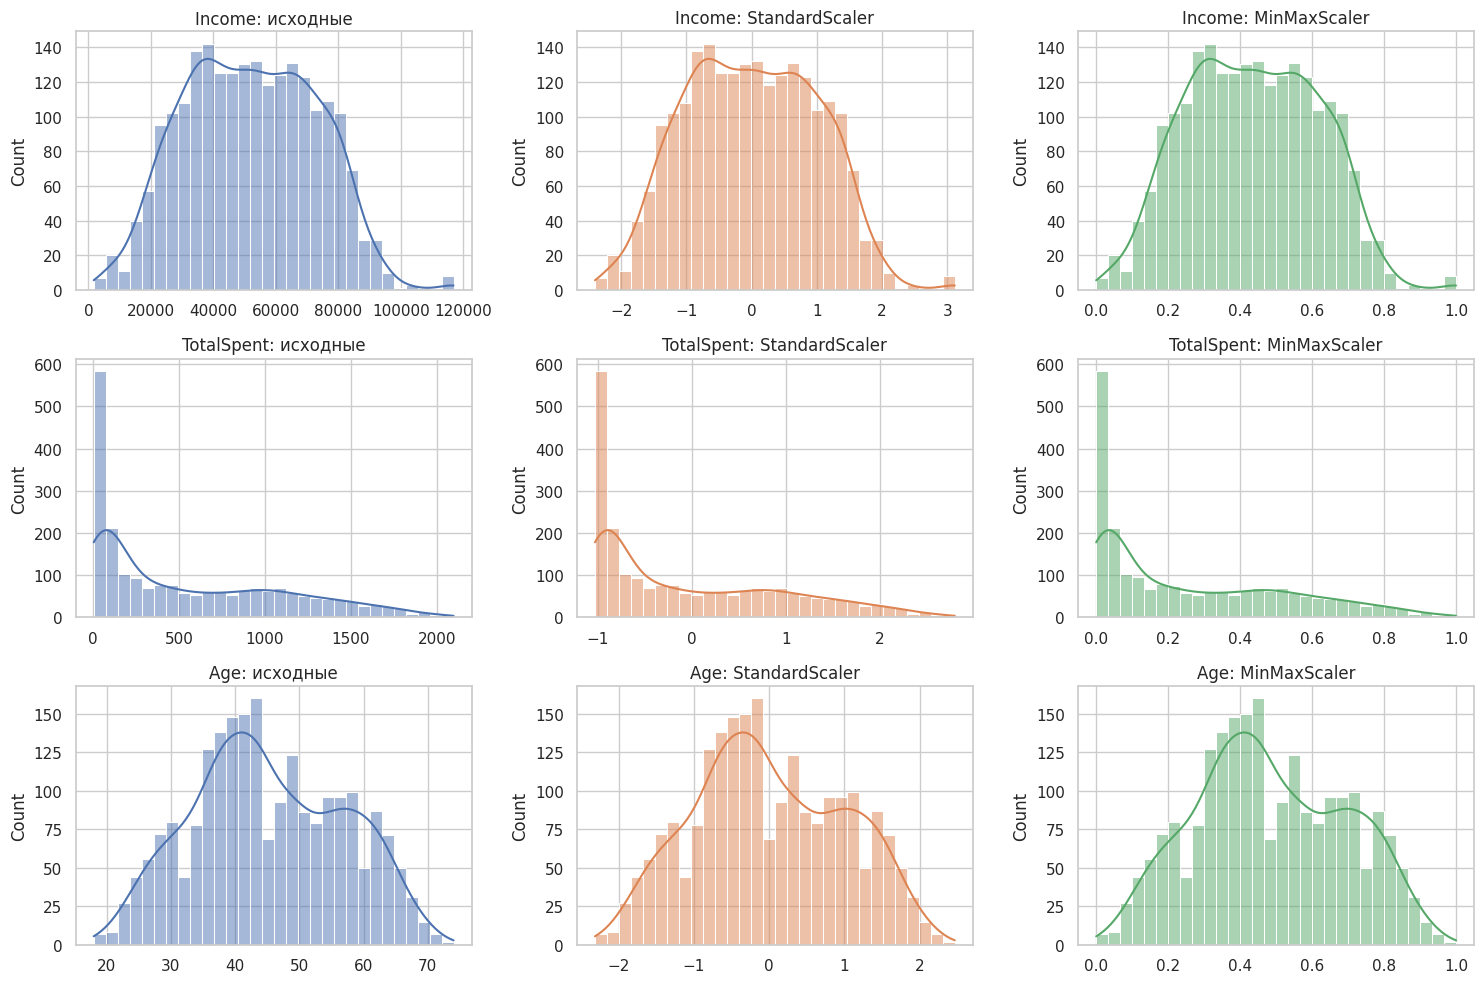

In [26]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for i, col in enumerate(["Income", "TotalSpent", "Age"]):
    sns.histplot(df_enc[col], bins=30, kde=True, ax=axes[i, 0], color="#4C72B0")
    sns.histplot(df_std[col], bins=30, kde=True, ax=axes[i, 1], color="#DD8452")
    sns.histplot(df_mm[col], bins=30, kde=True, ax=axes[i, 2], color="#55A868")
    axes[i, 0].set_title(f"{col}: исходные")
    axes[i, 1].set_title(f"{col}: StandardScaler")
    axes[i, 2].set_title(f"{col}: MinMaxScaler")
    for ax in axes[i]:
        ax.set_xlabel("")
save("10_scaling_hist")

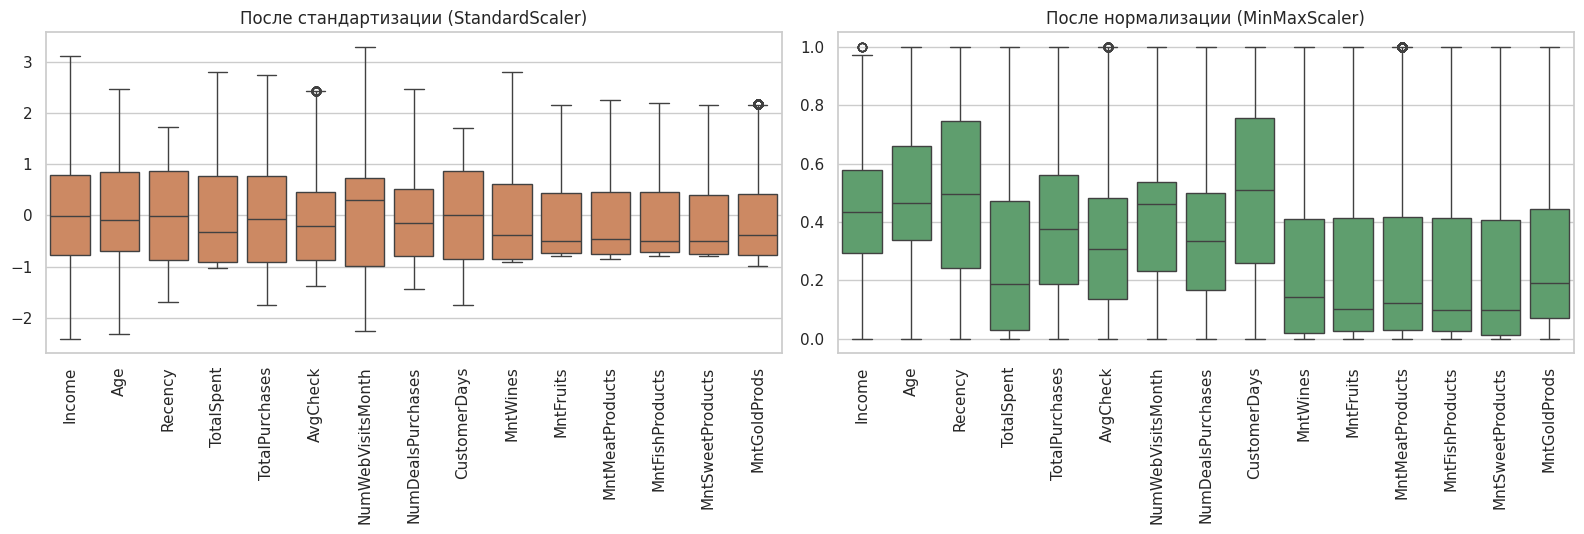

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.boxplot(data=df_std[scale_cols], ax=axes[0], color="#DD8452")
axes[0].set_title("После стандартизации (StandardScaler)")
sns.boxplot(data=df_mm[scale_cols], ax=axes[1], color="#55A868")
axes[1].set_title("После нормализации (MinMaxScaler)")
for ax in axes:
    ax.tick_params(axis="x", rotation=90)
save("11_scaling_box")

In [28]:
df_std.to_csv("marketing_data/marketing_prepared_std.csv", index=False)
df_mm.to_csv("marketing_data/marketing_prepared_minmax.csv", index=False)
print("Итоговый размер датасета:", df_std.shape)

Итоговый размер датасета: (2193, 47)
